# Dependence: covariance, joint tails, and extrapolation

We inspect three increasingly demanding descriptions of dependence: covariance matrices, copulas, and extreme-tail models. Generated data keep the population quantities visible. This lets us distinguish a stable estimate from a merely invertible matrix, and a fitted tail from a trustworthy extrapolation.

The sections use Convexity's dependence objects alongside its distribution and transform contracts. [Catalog and assumptions](../docs/dependence.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import dependence as dep, distributions as dist, transforms as tx

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True,
                     "grid.alpha": .18, "figure.dpi": 110})

## Shrinkage trades some bias for stability

Six coordinates share two factors. We deliberately estimate their covariance from only eighteen rows. The sample covariance is noisy; Ledoit–Wolf and OAS shrink toward a spherical target. A smaller distance to the generating matrix is useful in this simulation, but cannot be observed in a real dataset.

Read the table together with the heatmaps. The smallest eigenvalue describes numerical stability; distance to the population covariance describes estimation accuracy. Neither alone is a complete criterion.

In [2]:
loadings = np.array([[1.0, 0.2], [0.5, 1.0], [1.5, -0.4], [-0.2, 0.8], [0.7, 0.7], [1.0, -0.6]])
factors = rng.normal(size=(3000, 2))
observations = factors @ loadings.T + 0.4 * rng.normal(size=(3000, 6))
truth = dep.FactorCovariance(loadings, np.eye(2), np.full(6, 0.4 ** 2))
sample = dep.sample_covariance(observations)
small = observations[:18]
fits = {'Sample': dep.sample_covariance(small, ddof=0), 'Ledoit–Wolf': dep.LedoitWolf().fit(small), 'OAS': dep.OAS().fit(small), 'Fixed 20%': dep.ShrunkCovariance(0.2).fit(small)}
pd.DataFrame({name: {'shrinkage': fit.shrinkage, 'smallest eigenvalue': np.linalg.eigvalsh(fit.covariance)[0], 'distance to generating covariance': np.linalg.norm(fit.covariance - truth.covariance)} for name, fit in fits.items()}).T

,shrinkage,smallest eigenvalue,distance to generating covariance
Sample,NaN,0.078349,2.470910
Ledoit–Wolf,0.376589,0.430051,3.217703
OAS,0.273001,0.333308,2.982345
Fixed 20%,0.200000,0.265132,2.828169


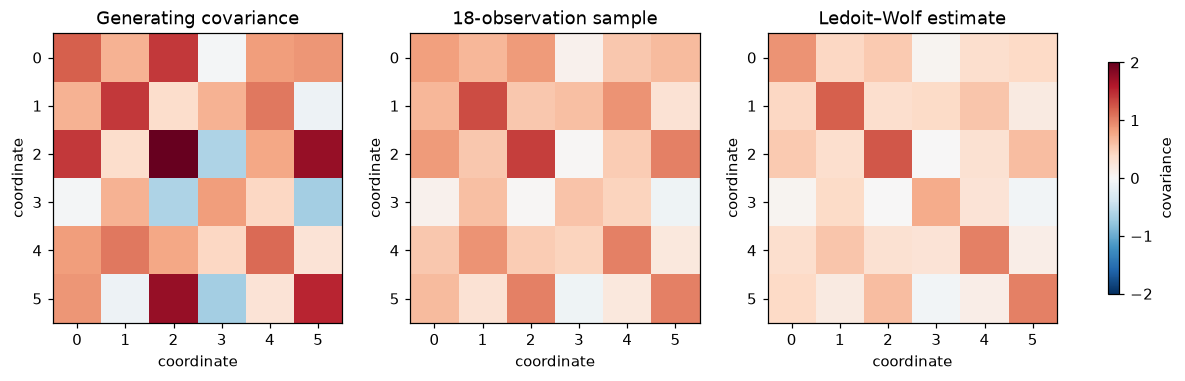

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), layout='constrained')
for ax, (name, matrix) in zip(axes, [('Generating covariance', truth.covariance), ('18-observation sample', fits['Sample'].covariance), ('Ledoit–Wolf estimate', fits['Ledoit–Wolf'].covariance)]):
    im = ax.imshow(matrix, cmap='RdBu_r', vmin=-2, vmax=2)
    ax.set(title=name, xlabel='coordinate', ylabel='coordinate')
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8, label='covariance')
plt.show()

## Memory length matters when covariance changes

EWMA weights recent observations more strongly. The effective count $1/\sum w_i^2$ measures weight concentration, not independence. We introduce a covariance change halfway through the series and compare finite-window sample estimates with two decay rates.

The faster EWMA should adapt sooner but fluctuate more. The reference line is the correlation of the generated regimes; all estimates use only rows available at their plotted cutoff.

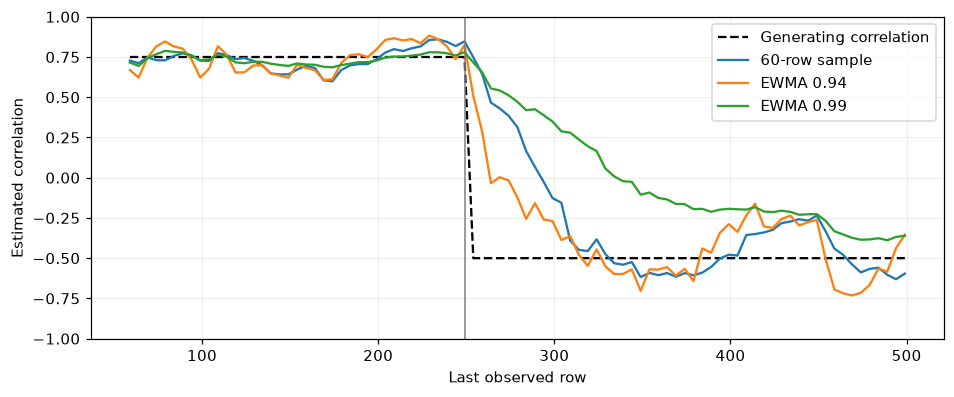

,decay,effective observations
0,0.94,32.333333
1,0.99,196.402018


In [4]:
before = dist.multivariate_normal([0., 0.], [[1., .75], [.75, 1.]]).sample(250, rng=rng)
after = dist.multivariate_normal([0., 0.], [[1., -.5], [-.5, 1.]]).sample(250, rng=rng)
changing = np.vstack((before, after))
ends = np.arange(60, len(changing)+1, 5)
estimates = {"60-row sample": [], "EWMA 0.94": [], "EWMA 0.99": []}
for stop in ends:
    estimates["60-row sample"].append(dep.sample_covariance(changing[stop-60:stop]).correlation[0, 1])
    for decay in (.94, .99):
        estimates[f"EWMA {decay}"].append(dep.ewma_covariance(changing[:stop], decay=decay).correlation[0, 1])
fig, ax = plt.subplots()
ax.plot(ends-1, np.where(ends <= 250, .75, -.5), "k--", label="Generating correlation")
for label, values in estimates.items():
    ax.plot(ends-1, values, label=label)
ax.axvline(249.5, color="gray", linewidth=1)
ax.set(xlabel="Last observed row", ylabel="Estimated correlation", ylim=(-1, 1))
ax.legend()
plt.show()
pd.DataFrame({"decay": [.94, .99], "effective observations": [
    dep.ewma_covariance(changing, decay=decay).effective_nobs for decay in (.94, .99)]})

## Factor structure is a covariance assumption

Observed-factor OLS with a full residual covariance reproduces the sample covariance decomposition. Restricting residual covariance to its diagonal removes residual cross-dependence. Latent factor analysis instead estimates both the common structure and coordinate noise.

The table compares these choices against the generating covariance. A smaller parameterization can help with scarce data, while incorrect factor or residual structure can introduce systematic error.

In [5]:
observed_factors = dep.fit_factor_covariance(observations, factors, residual='full')
latent = tx.FactorAnalysis(2).fit(observations)
composed = dep.FactorCovariance(latent.loadings, np.eye(2), latent.noise_variance, location=latent.location)
pd.DataFrame({'generating noise': np.full(6, 0.16), 'fitted latent noise': latent.noise_variance})

,generating noise,fitted latent noise
0,0.16,0.157073
1,0.16,0.157449
2,0.16,0.151362
3,0.16,0.167034
4,0.16,0.157437
5,0.16,0.161628


In [6]:
diagonal_factors = dep.fit_factor_covariance(observations, factors, residual="diagonal")
pd.DataFrame({label: {"covariance error": np.linalg.norm(estimate.covariance-truth.covariance),
                     "equal-weight variance": np.ones(6) @ estimate.covariance @ np.ones(6)/36}
              for label, estimate in {"Sample": sample, "Observed factors, full residual": observed_factors,
                  "Observed factors, diagonal residual": diagonal_factors, "Latent factors": composed}.items()}).T

,covariance error,equal-weight variance
Sample,0.225135,0.660494
"Observed factors, full residual",0.225135,0.660494
"Observed factors, diagonal residual",0.226524,0.659655
Latent factors,0.226086,0.660232


## Repairing a matrix does not establish its empirical validity

An estimated or assembled covariance must be positive semidefinite. Spectral projection repairs eigenvalues; nearest-correlation projection also fixes the diagonal at one. Those are explicit mathematical changes to the supplied matrix.

The input below implies a correlation greater than one. Inspect how each repair changes the spectrum. A repaired matrix can be used mathematically, but its distance from the input is not an estimate of statistical uncertainty.

In [7]:
invalid = np.array([[1.0, 1.2], [1.2, 1.0]])
psd = dep.PositiveSemidefinite(min_eigenvalue=1e-06).project(invalid)
unit = dep.nearest_correlation(invalid, min_eigenvalue=1e-06)
pd.DataFrame({'input': np.linalg.eigvalsh(invalid), 'PSD projection': np.linalg.eigvalsh(psd.matrix), 'unit-diagonal projection': np.linalg.eigvalsh(unit.matrix)}, index=['minimum', 'maximum'])

,input,PSD projection,unit-diagonal projection
minimum,-0.2,1.000000e-06,0.000001
maximum,2.2,2.200000e+00,1.999999


## Heavy tails: distinguish shape from covariance

The t distribution has a shared random scale across coordinates. Its covariance is $\nu/(\nu-2)$ times its shape for $\nu>2$, and does not exist for $\nu\leq2$. An optimizer's fitted degrees of freedom can therefore change the interpretation of its second moments.

We fit a generated t sample, then inspect the parameter estimates and how conditioning on one coordinate shifts the other.

In [8]:
correlation = np.array([[1.0, 0.6], [0.6, 1.0]])
heavy = dep.multivariate_student_t(6, [0.0, 1.0], correlation)
draws = heavy.sample(6000, rng=rng)
fitted_t = dep.StudentT(df=5.0, estimate_df=True).fit(draws)

In [9]:
pd.DataFrame({"generating": [6., 0., 1., 1.5, 1.5],
              "estimated": [fitted_t.df, *fitted_t.location, *np.diag(fitted_t.covariance)]},
             index=["degrees of freedom", "location 0", "location 1", "variance 0", "variance 1"])

,generating,estimated
degrees of freedom,6.0,5.838202
location 0,0.0,0.029447
location 1,1.0,1.014148
variance 0,1.5,1.526811
variance 1,1.5,1.536462


## Equal rank dependence can conceal different joint tails

These four copulas have the same population Kendall tau of 0.5. Their asymptotic tail dependence differs: a Gaussian copula has no positive tail-dependence coefficient; a t copula has both upper and lower tail dependence; Clayton and Gumbel concentrate it in opposite tails.

Uniform coordinates remove marginal scales. Compare the corner patterns and the tail-coefficient table. A coefficient is a limiting quantity; finite-threshold exceedance rates will not match it exactly.

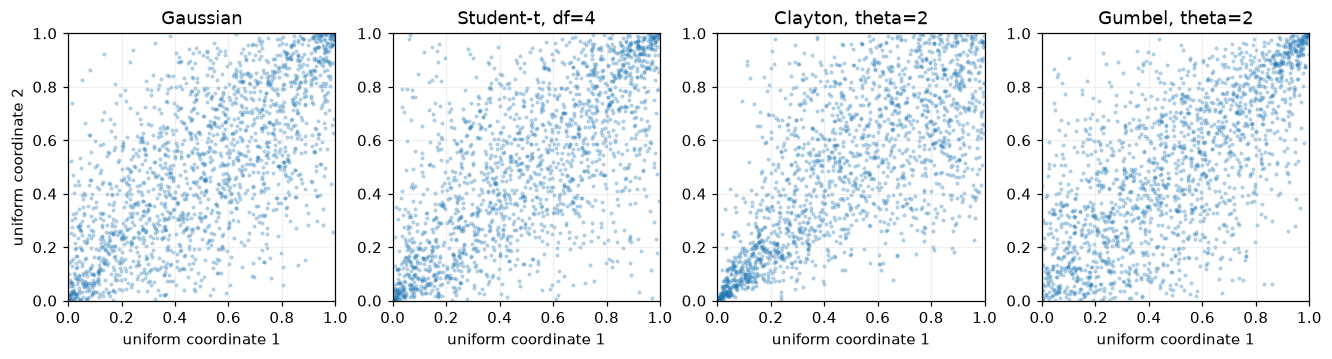

,lower tail coefficient,upper tail coefficient
Gaussian,0.000000,0.000000
"Student-t, df=4",0.396843,0.396843
"Clayton, theta=2",0.707107,0.000000
"Gumbel, theta=2",0.000000,0.585786


In [10]:
rho = np.sin(np.pi / 4)
rank_correlation = [[1.0, rho], [rho, 1.0]]
copulas = {'Gaussian': dep.GaussianCopula(rank_correlation), 'Student-t, df=4': dep.StudentTCopula(rank_correlation, 4), 'Clayton, theta=2': dep.ClaytonCopula(2), 'Gumbel, theta=2': dep.GumbelCopula(2)}
fig, axes = plt.subplots(1, 4, figsize=(12, 3), layout='constrained')
for ax, (name, copula) in zip(axes, copulas.items()):
    uniforms = copula.sample(1800, rng=rng)
    ax.scatter(*uniforms.T, s=3, alpha=0.25)
    ax.set(title=name, xlabel='uniform coordinate 1', xlim=(0, 1), ylim=(0, 1))
    ax.set_aspect('equal')
axes[0].set_ylabel('uniform coordinate 2')
plt.show()
pd.DataFrame({name: copula.tail_dependence() for name, copula in copulas.items()}, index=['lower tail coefficient', 'upper tail coefficient']).T

## Change the marginals without changing the copula

Sklar composition separates marginal distributions from rank dependence. The example combines a t copula with a positive lognormal coordinate and a Gaussian coordinate. The joint cloud is no longer elliptically symmetric, even though the copula is unchanged.

Rank fitting estimates a dependence parameter from pseudo-observations; its likelihood is a pseudo-likelihood. A supplied t degrees of freedom is still an assumption because Kendall tau alone cannot identify it.

In [11]:
copula = dep.StudentTCopula(correlation, 6)
rank_fit = dep.fit_copula(draws, family='student_t', df=6)
mixed = dep.CopulaDistribution(copula, [dist.lognormal(log_scale=0.4), dist.normal(2, 3)])
mixed_samples = mixed.sample(1000, rng=rng)

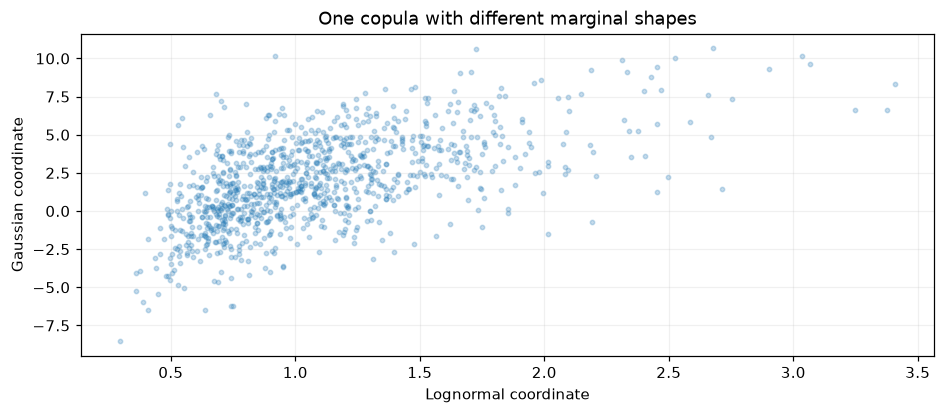

,population latent correlation,rank-fitted correlation
0,0.6,0.61018


In [12]:
fig, ax = plt.subplots()
ax.scatter(mixed_samples[:, 0], mixed_samples[:, 1], s=8, alpha=.25)
ax.set(xlabel="Lognormal coordinate", ylabel="Gaussian coordinate", title="One copula with different marginal shapes")
plt.show()
pd.DataFrame({"population latent correlation": [.6],
              "rank-fitted correlation": [rank_fit.copula.correlation[0, 1]]})

## Peaks over threshold: extrapolation is in original observation units

The generalized Pareto law describes **excesses conditional on crossing a threshold**. Multiplying its survival probability by the crossing rate returns a probability in the original sample. A return period of 1,000 below means 1,000 original observations, not 1,000 exceedances.

The generated tail is exactly GPD above the chosen threshold, so this is a favourable fitting experiment. Inspect agreement in the observed region and divergence at long return periods. No uncertainty band is implied by the fitted curve.

In [13]:
threshold = 3.0
excess_law = dep.generalized_pareto(0.2, scale=1.5)
excesses = excess_law.sample(4000, rng=rng)
tail_data = np.r_[np.zeros(16000), threshold + excesses]
pot = dep.peaks_over_threshold(tail_data, threshold)
periods = np.geomspace(5, 10000, 120)
levels = pot.return_level(periods)
pd.DataFrame({'period (observations)': [10, 100, 1000], 'return level': pot.return_level([10, 100, 1000])})

,period (observations),return level
0,10,4.101161
1,100,9.181262
2,1000,17.480721


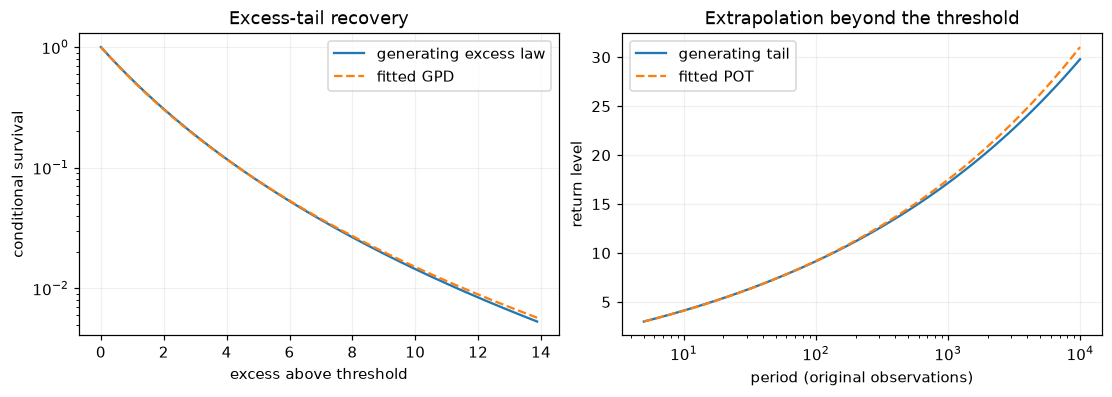

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
grid = np.linspace(0, np.quantile(excesses, 0.995), 250)
axes[0].semilogy(grid, excess_law.survival(grid), label='generating excess law')
axes[0].semilogy(grid, pot.tail.distribution.survival(grid), '--', label='fitted GPD')
axes[0].set(xlabel='excess above threshold', ylabel='conditional survival', title='Excess-tail recovery')
axes[0].legend()
generating_levels = threshold + 1.5 / 0.2 * ((0.2 * periods) ** 0.2 - 1)
axes[1].semilogx(periods, generating_levels, label='generating tail')
axes[1].semilogx(periods, levels, '--', label='fitted POT')
axes[1].set(xlabel='period (original observations)', ylabel='return level', title='Extrapolation beyond the threshold')
axes[1].legend()
plt.show()

## Block maxima use a different clock

Block maxima discard all but one observation per block. Their GEV return periods count blocks, so they cannot be compared directly with the POT periods above. Convexity exposes the conventional extreme-value index $\xi$, where positive means a heavy upper tail; it maps the opposite SciPy parameter sign internally.

Exponential observations lie in the Gumbel domain, but finite blocks do not produce an exact Gumbel law. A nonzero fitted shape can reflect finite-block approximation as well as sampling error.

In [15]:
series = rng.exponential(size=24000)
maxima = dep.block_maxima(series, block_size=24)
gev = dep.GeneralizedExtremeValue().fit(maxima)
return_periods = np.array([10.0, 100.0, 1000.0])
pd.DataFrame({'period (blocks)': return_periods, 'return level': gev.return_level(return_periods)})

,period (blocks),return level
0,10.0,5.469003
1,100.0,7.935257
2,1000.0,10.529548


For a less favourable experiment, change the POT threshold or reduce the number of exceedances. Also compare sample covariance and shrinkage after rescaling one coordinate: the spherical shrinkage target depends on units. Threshold selection, clustered extremes, and parameter uncertainty require additional modelling; these examples do not infer them automatically.